### Setups

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

import sys
from pathlib import Path

SRC = Path.cwd().parents[1] / "PCM" / "src"
sys.path.insert(0, str(SRC))

from personai_pcms.model_getter_funcs import make_random_forest_classifier

os.makedirs("../figures/learning_curves", exist_ok=True)

df_p = pd.read_csv("../../data/personai/final_main_dataset_no_missing_ALLENC_with_time_and_hr_age.csv")
df_d = pd.read_csv("../../data/dorn/DORN_env_phy_231.csv")

### Find user with most datapoints

In [2]:
counts_p = df_p["user_id"].value_counts()
top_user_p = counts_p.idxmax()
top_count_p = counts_p.max()

counts_d = df_d["user_id"].value_counts()
top_user_d = counts_d.idxmax()
top_count_d = counts_d.max()

print("PersonAI:")
print("User with most datapoints:", top_user_p)
print("Number of datapoints:", top_count_p)

print("DORN:")
print("User with most datapoints:", top_user_d)
print("Number of datapoints:", top_count_d)

PersonAI:
User with most datapoints: id003
Number of datapoints: 289
DORN:
User with most datapoints: dorn1
Number of datapoints: 231


### PersonAI learning curve

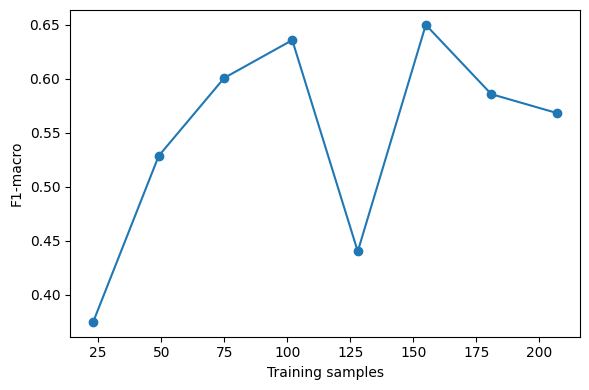

In [3]:
df_user_p = df_p[df_p["user_id"] == top_user_p]

X = df_user_p[["t_ubi", "rh_ubi", "hr_ubi", "bpm_time_diff_log", "CO2", "activity"]]
y = df_user_p["thermal_cozie"].astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

train_fracs = np.linspace(0.1, 0.9, 8)
scores = []
train_ns = []

for frac in train_fracs:
    X_sub, _, y_sub, _ = train_test_split(
        X_train_full, y_train_full, train_size=frac, stratify=y_train_full, random_state=42
    )

    #clf, _, _ = make_random_forest_classifier_with_standard_scaler()
    clf, _, _ = make_random_forest_classifier()
    clf.fit(X_sub, y_sub)

    y_pred = clf.predict(X_test)
    scores.append(f1_score(y_test, y_pred, average="macro"))
    train_ns.append(len(X_sub))

pd.DataFrame({
    "training_samples": train_ns,
    "f1_macro": scores
}).to_csv(
    f"../figures/learning_curves/learning_curve_pcm_f1macro_personai_{top_user_p}.csv",
    index=False
)

plt.figure(figsize=(6,4))
plt.plot(train_ns, scores, marker="o")
plt.xlabel("Training samples")
plt.ylabel("F1-macro")
#plt.title("Learning Curve PCM (F1-macro) - PersonAI - " + top_user_p)
plt.tight_layout()
plt.savefig(f"../figures/learning_curves/learning_curve_pcm_f1macro_personai_{top_user_p}.pdf")
plt.show()

### Dorn learning curve

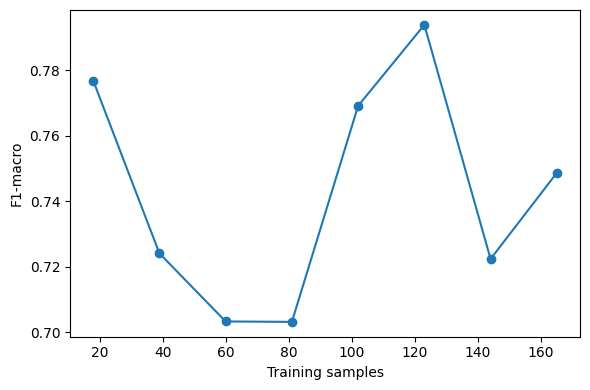

In [5]:
df_user = df_d[df_d["user_id"] == top_user_d].copy()

# encode categoricals
df_user["clothing"] = LabelEncoder().fit_transform(df_user["clothing"])

X = df_user[["clothing", "heartRate", "t-nb", "t-ubi", "rh-ubi"]]
y = df_user["thermal_cozie"].astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

train_fracs = np.linspace(0.1, 0.9, 8)
scores = []
train_ns = []

for frac in train_fracs:
    X_sub, _, y_sub, _ = train_test_split(
        X_train_full, y_train_full, train_size=frac, stratify=y_train_full, random_state=42
    )

    #clf, _, _ = make_random_forest_classifier_with_standard_scaler()
    clf, _, _ = make_random_forest_classifier()
    clf.fit(X_sub, y_sub)

    y_pred = clf.predict(X_test)
    scores.append(f1_score(y_test, y_pred, average="macro"))
    train_ns.append(len(X_sub))

pd.DataFrame({
    "training_samples": train_ns,
    "f1_macro": scores
}).to_csv(
    f"../figures/learning_curves/learning_curve_pcm_f1macro_dorn_{top_user_d}.csv",
    index=False
)

plt.figure(figsize=(6,4))
plt.plot(train_ns, scores, marker="o")
plt.xlabel("Training samples")
plt.ylabel("F1-macro")
#plt.title("Learning Curve PCM (F1-macro) - DORN - " + top_user_d)
plt.tight_layout()
plt.savefig(f"../figures/learning_curves/learning_curve_pcm_f1macro_dorn_{top_user_d}.pdf")
plt.show()

### PersonAI learning curve precision/recall

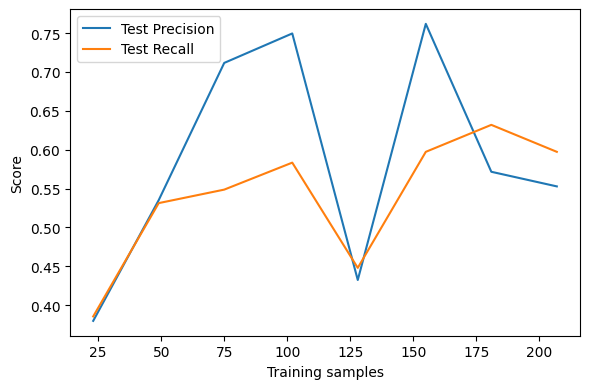

In [6]:
df_user_p = df_p[df_p["user_id"] == top_user_p]

X = df_user_p[["t_ubi", "rh_ubi", "hr_ubi", "bpm_time_diff_log", "CO2", "activity"]]
y = df_user_p["thermal_cozie"].astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

train_fracs = np.linspace(0.1, 0.9, 8)
train_ns = []
test_precision = []
test_recall = []

for frac in train_fracs:
    X_sub, _, y_sub, _ = train_test_split(
        X_train_full, y_train_full, train_size=frac, stratify=y_train_full, random_state=42
    )

    #clf, _, _ = make_random_forest_classifier_with_standard_scaler()
    clf, _, _ = make_random_forest_classifier()
    clf.fit(X_sub, y_sub)

    y_pred = clf.predict(X_test)
    scores.append(f1_score(y_test, y_pred, average="macro"))
    test_precision.append(precision_score(y_test, y_pred, average="macro"))
    test_recall.append(recall_score(y_test, y_pred, average="macro"))    
    train_ns.append(len(X_sub))

pd.DataFrame({
    "training_samples": train_ns,
    "precision_macro": test_precision,
    "recall_macro": test_recall
}).to_csv(
    f"../figures/learning_curves/learning_curve_pcm_precision_recall_personai_{top_user_p}.csv",
    index=False
)

plt.figure(figsize=(6,4))
plt.plot(train_ns, test_precision, label="Test Precision")
plt.plot(train_ns, test_recall, label="Test Recall")
plt.xlabel("Training samples")
plt.ylabel("Score")
#plt.title("Learning Curve PCM (Precision and Recall) - PersonAI - " + top_user_p)
plt.legend()
plt.tight_layout()
plt.savefig(f"../figures/learning_curves/learning_curve_pcm_precision_recall_personai_{top_user_p}.pdf")
plt.show()

### Dorn learning curve precision/recall

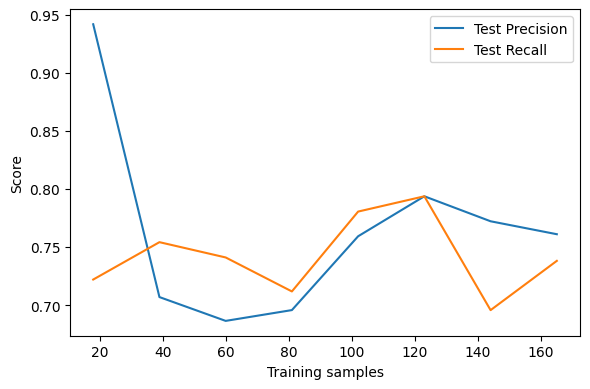

In [7]:
df_user = df_d[df_d["user_id"] == top_user_d].copy()

# encode categoricals
df_user["clothing"] = LabelEncoder().fit_transform(df_user["clothing"])

X = df_user[["clothing", "heartRate", "t-nb", "t-ubi", "rh-ubi"]]
y = df_user["thermal_cozie"].astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

train_fracs = np.linspace(0.1, 0.9, 8)
train_ns = []
test_precision = []
test_recall = []

for frac in train_fracs:
    X_sub, _, y_sub, _ = train_test_split(
        X_train_full, y_train_full, train_size=frac, stratify=y_train_full, random_state=42
    )

    #clf, _, _ = make_random_forest_classifier_with_standard_scaler()
    clf, _, _ = make_random_forest_classifier()
    clf.fit(X_sub, y_sub)

    y_pred = clf.predict(X_test)
    test_precision.append(precision_score(y_test, y_pred, average="macro"))
    test_recall.append(recall_score(y_test, y_pred, average="macro")) 
    train_ns.append(len(X_sub))

pd.DataFrame({
    "training_samples": train_ns,
    "precision_macro": test_precision,
    "recall_macro": test_recall
}).to_csv(
    f"../figures/learning_curves/learning_curve_pcm_precision_recall_dorn_{top_user_d}.csv",
    index=False
)

plt.figure(figsize=(6,4))
plt.plot(train_ns, test_precision, label="Test Precision")
plt.plot(train_ns, test_recall, label="Test Recall")
plt.legend()
plt.xlabel("Training samples")
plt.ylabel("Score")
#plt.title("Learning Curve PCM (Precision and Recall) - DORN - " + top_user_d)
plt.tight_layout()
plt.savefig(f"../figures/learning_curves/learning_curve_pcm_precision_recall_dorn_{top_user_d}.pdf")
plt.show()